In [29]:
import os
import sys
from pathlib import Path

# Add the project root (one level up from the notebooks folder) to the Python path
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

print(f"Added {project_root} to Python path.")


Added /Users/fionaxie/OMSC/DL2026/mnist-math to Python path.


In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [35]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
#from sklearn.manifold import TSNE

from data_pipeline import get_arithmetic_dataloader
from models.jepa_model import IJepaModel
from utils.experiment_config import load_experiment_config, apply_cli_overrides
from utils.common import get_device, set_seed
from evaluation.metrics import rollout_evaluation


In [74]:
def load_model_from_run(run_dir: Path):
    config = load_experiment_config(Path(run_dir) / "config.json")
    #config = apply_cli_overrides(config, {})
    set_seed(config.run.seed)
    device = get_device()
    
    if config.model.op_embedding_type == "embedding":
        model_ops = sorted(list(set(config.data.ops) | set(test_ops)))
    else:
        model_ops = config.data.ops

    encoder_kwargs: dict[str, Any] = {
        'normalize': config.model.encoder_normalize,
        'activation': config.model.activation
    }
    if config.model.encoder_type.lower() in ['mlp', 'cnn']:
        encoder_kwargs['hidden_dim'] = config.model.encoder_hidden_dim

    elif config.model.encoder_type.lower() == 'vit':
        encoder_kwargs.update({
            "patch_size": config.model.patch_size,
            "d_model": config.model.d_model,
            "depth": config.model.depth,
            "nhead": config.model.nhead,
            "mlp_dim": config.model.mlp_dim,
            "use_cls_token": config.model.use_cls_token
        })
    classifier_kwargs = {'num_classes': config.model.num_classes,
                         'hidden_dim': config.model.classifier_hidden_dim}
    kwargs_model: dict[str, Any] = {'encoder_kwargs': encoder_kwargs, 'classifier_kwargs': classifier_kwargs}

    kwargs_vicreg: dict[str, Any] = {'cls_loss_weight': config.optim.cls_weight,
                                    'use_vic_reg': config.model.use_vic_reg,
                                    'lamda': config.model.lamda,
                                    'gamma': config.model.gamma,
                                    'miu': config.model.miu,
                                    'nu': config.model.nu}

    kwargs_comp: dict[str, Any] = {'use_composition_loss': getattr(config.model, 'use_composition_loss', False),
                                   'composition_lambda': getattr(config.model, 'composition_lambda', 0.0),
                                   'training_ops': config.data.ops,
                                   'composition_ops': getattr(config.model, 'composition_ops', []),
                                   'composition_detach_teacher': getattr(config.model, 'composition_detach_teacher', True)}

    model = IJepaModel(
        ops=model_ops,
        latent_dim=config.model.latent_dim,
        op_embed_dim=config.model.op_embed_dim,
        op_embedding_type=config.model.op_embedding_type,
        encoder_type=config.model.encoder_type,
        predictor_hidden_dim=tuple(config.model.predictor_hidden_dim),
        predictor_dropout=config.model.predictor_dropout,
        predictor_normalize=config.model.predictor_normalize,
        predictor_type=config.model.predictor_type,
        residual_scale_init=config.model.residual_scale_init,
        rotation_angle_init=config.model.rotation_angle_init,
        rotation_learnable=config.model.rotation_learnable,
        rotation_init_mode=config.model.rotation_init_mode,
        rotation_period=config.model.rotation_period,
        joint_cls_training=config.optim.cls_weight > 0,
        momentum =config.model.momentum,
        **kwargs_model
    ).to(device)

    ckpt = torch.load(run_dir / "checkpoint_final.pt", map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    model.eval()
    print(f'Model is saved at epoch = {ckpt["epoch"]} ')

    return model, config
    #model, config = load_model_from_run(JEPA_PRIMITIVE_DIR)

In [76]:
run_dir = (
    Path(project_root) / "runs/jepa/20260429-131035-primitive_ops1_mlp"
)
model_op1, config_op1 = load_model_from_run(run_dir)

Model is saved at epoch = 10 


In [33]:
def load_data(config, test_ops = None):
     # Use test_ops if specified, otherwise default to training ops
    if test_ops is None:
        test_ops = config.data.test_ops if config.data.test_ops else config.data.ops

    train_loader = get_arithmetic_dataloader(
        dataset_name=config.data.dataset,
        batch_size=config.data.batch_size,
        ops=config.data.ops,
        is_train=True,
        data_root=config.data.data_root,
        num_workers=config.data.num_workers,
    )
    seen_test_loader = None
    if test_ops != config.data.ops:
        seen_test_loader = get_arithmetic_dataloader(
            dataset_name=config.data.dataset,
            batch_size=config.data.batch_size,
            ops=config.data.ops,
            is_train=False,
            data_root=config.data.data_root,
            num_workers=config.data.num_workers,
        )

    test_loader = get_arithmetic_dataloader(
        dataset_name=config.data.dataset,
        batch_size=config.data.batch_size,
        ops=test_ops,
        is_train=False,
        data_root=config.data.data_root,
        num_workers=config.data.num_workers,
    )

    if config.run.overfit > 0:
        # this section is not needed.
        snap = FixedSampleDataset(train_loader.dataset, config.run.overfit)
        bs = min(config.data.batch_size, config.run.overfit)
        train_loader = DataLoader(
            snap,
            batch_size=bs,
            shuffle=True,
            num_workers=config.data.num_workers,
        )
        test_loader = DataLoader(
            snap,
            batch_size=bs,
            shuffle=False,
            num_workers=config.data.num_workers,
        )
        seen_test_loader = test_loader
        print(f"[overfit] snapshotted {config.run.overfit} samples (train == eval set)")
    return {
        'train_loader':train_loader,
        'test_loader':test_loader,
        'seen_test_loader':seen_test_loader
    }
    

In [34]:
def compute_rollout_accuracies(premitive_ops, scales, run_dir, device):
    knn_accuracies = []
    cls_accuracies = []
    cls_losses = []
    #model, config = load_model_from_run(run_dir)
    
    for scale in scales:
        test_ops = list(premitive_ops * scale)
        print (scale, test_ops)
        model, config = load_model_from_run(run_dir)
        dataloader = load_data(config, test_ops = test_ops)
        rollout_accuracy = rollout_evaluation(model, dataloader['test_loader'], 
                                              device, config.data.ops, test_ops, config.model.num_classes)
        knn_accuracies.append([scale, rollout_accuracy['knn_accuracy']])
        cls_accuracies.append([scale, rollout_accuracy['cls_accuracy']])
        cls_losses.append([scale, rollout_accuracy['cls_loss']])
    return {
        'knn_accuracies': np.array(knn_accuracies),
        'cls_accuracies': np.array(cls_accuracies),
        'cls_losses': np.array(cls_losses)
    }

## 1. Test the robustness of roll-out compositional operations on different primitive operations 
#### Make sure checkpoint.pt is the model at the end of training instead of the one with best_accuracy if model evaluation fails and best_accuracy is useless.  

In [67]:
def plot_rollout_accuracy(accuracies: dict[str, np.ndarray], primitive_ops = None):
    knn_accuracies = accuracies['knn_accuracies']
    cls_accuracies = accuracies['cls_accuracies']
    cls_losses = accuracies['cls_losses']
    fig, ax1 = plt.subplots()
    ax1.plot(knn_accuracies[:, 0], knn_accuracies[:,1], '.-', color='r', label='knn_accuracy')
    ax1.plot(cls_accuracies[:, 0], cls_accuracies[:,1], '.-', color = 'k',label='cls_accuracy')
    ax1.legend(loc='lower left')
    ax1.set_ylim([0.9, 1])
    ax2 = ax1.twinx()
    ax2.plot(cls_losses[:, 0], cls_losses[:,1], '.-', color = 'b', label='test_loss')
    ax2.legend(loc= 'upper right')
    ax2.set_ylim([0, 0.2])
    
    ax1.set_xlabel('Scale')
    ax1.set_ylabel('Accuracies')
    ax2.set_ylabel('Loss')
    

### 1.1 primitive operations = [+1, -1] 

In [48]:
jepa_primitive_op_1_dir= (
    Path(project_root) / "runs/jepa/20260428-154450-primitive_ops1_mlp"
)
scales = np.arange(1, 10)
premitive_ops = np.array([+1, -1])
device = get_device()
run_dir = jepa_primitive_op_1_dir
primitive_op1_results = compute_rollout_accuracies(premitive_ops, scales, run_dir, device)

1 [np.int64(1), np.int64(-1)]
2 [np.int64(2), np.int64(-2)]
3 [np.int64(3), np.int64(-3)]
4 [np.int64(4), np.int64(-4)]
5 [np.int64(5), np.int64(-5)]
6 [np.int64(6), np.int64(-6)]
7 [np.int64(7), np.int64(-7)]
8 [np.int64(8), np.int64(-8)]
9 [np.int64(9), np.int64(-9)]


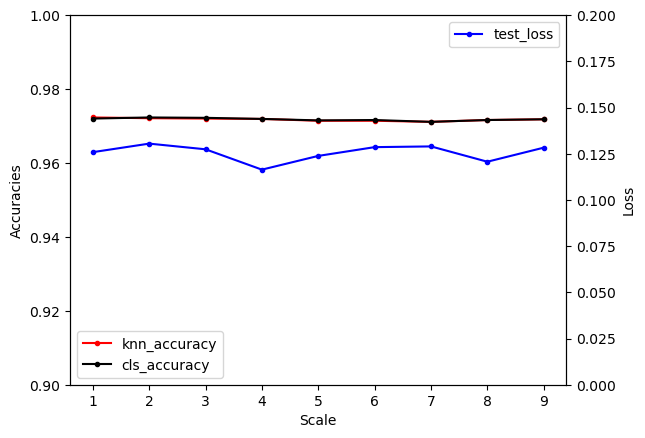

In [68]:
plot_rollout_accuracy(primitive_op1_results)


### 1.2 primitive operations = [+2, -2] 

In [66]:
jepa_primitive_op_2_dir = (
    Path(project_root) / "runs/jepa/20260428-144606-primitive_ops2_mlp"
)
print(run_dir)
scales = np.arange(1, 10)
premitive_ops = np.array([+2, -2])
device = get_device()
run_dir = jepa_primitive_op_2_dir
primitive_op2_results = compute_rollout_accuracies(premitive_ops, scales, run_dir, device)

/Users/fionaxie/OMSC/DL2026/mnist-math/runs/jepa/20260428-144606-primitive_ops2_mlp
1 [np.int64(2), np.int64(-2)]
2 [np.int64(4), np.int64(-4)]
3 [np.int64(6), np.int64(-6)]
4 [np.int64(8), np.int64(-8)]
5 [np.int64(10), np.int64(-10)]
6 [np.int64(12), np.int64(-12)]
7 [np.int64(14), np.int64(-14)]
8 [np.int64(16), np.int64(-16)]
9 [np.int64(18), np.int64(-18)]


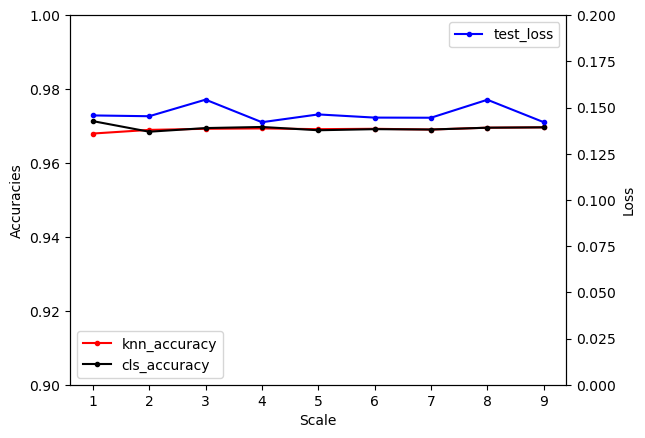

In [69]:
plot_rollout_accuracy(primitive_op2_results)

### 1.3 Compare the latent space in primitive op1 and primitive op2

In [70]:
from evaluation.metrics import collect_latent_diagnostics

In [ ]:
model_op1, config_op1 = load_model_from_run(jepa_primitive_op_2_dir)
premitive_ops = np.array([+1, -1])
test_ops = premitive_ops 
dataloader = load_data(config_op1, test_ops = test_ops)
latents_op1 = collect_latent_diagnostics(
        model_op1,
        dataloader,
        device: torch.device,
        config_op1.model.num_classes,


In [ ]:
model_op1, config_op1 = load_model_from_run(jepa_primitive_op_2_dir)

### 1.4 Compare the action embedding in primitive op1 and oprimitive op2